LOADED ARTIFACTS
Model      : pipeline_comparison_artifacts\focal_asl_only_best.pt
Scaler     : pipeline_comparison_artifacts\feature_scaler.pkl
Features   : 33
Targets    : ['CPU', 'Memory', 'Cache', 'IO', 'Lock', 'ContextSwitch']

Dataset shape: (694819, 53)

SINGLE INPUT TEST CASE


,ctx_switches,voluntary_switches,involuntary_switches,cpu_migrations,total_runtime_ns,stall_ns,avg_stall_ns,max_stall_ns,latency_count,minor_faults,...,avg_futex_latency_ns,epoll_count,avg_epoll_latency_ns,poll_count,syscall_error_count,mutex_contentions,avg_mutex_wait_ns,max_mutex_wait_ns,rwsem_read_contentions,avg_rwsem_read_wait_ns
0,5,0,5,1,38541,58630,58630,58630,1,155,...,6328,0,0,0,0,23,282,401,7,273


d:\Code\ProjectA\PerformanceBottleneckDiagnosis\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Model Pred


,Bottleneck,Probability,Prediction
0,CPU,0.8063,1
1,Memory,0.7997,1
2,Cache,0.3752,0
3,IO,0.6838,1
4,Lock,0.6204,1
5,ContextSwitch,0.3777,0


...

,Feature,Input Value,Attribution
0,total_runtime_ns,38541,1.646465
1,stall_ns,58630,0.342591
2,avg_stall_ns,58630,-0.301100
3,max_stall_ns,58630,-0.280808
4,futex_count,31,-0.245537
5,syscall_count,38,-0.243090
6,ctx_switches,5,-0.176638
7,latency_count,1,0.153614
8,voluntary_switches,0,-0.147934
9,rwsem_read_contentions,7,0.128728



--- Lock ---


,Feature,Input Value,Attribution
0,total_runtime_ns,38541,4.625840
1,max_stall_ns,58630,-1.662453
2,avg_stall_ns,58630,-1.248883
3,involuntary_switches,5,-0.428098
4,ctx_switches,5,-0.347929
5,voluntary_switches,0,-0.316272
6,syscall_count,38,-0.273209
7,futex_count,31,-0.252178
8,rwsem_read_contentions,7,0.233597
9,max_mutex_wait_ns,401,-0.175270



--- ContextSwitch ---


,Feature,Input Value,Attribution
0,stall_ns,58630,-5.433612
1,avg_stall_ns,58630,-4.044041
2,max_stall_ns,58630,-2.849927
3,involuntary_switches,5,2.149428
4,futex_count,31,1.849651
5,syscall_count,38,1.802250
6,cpu_migrations,1,-1.375356
7,latency_count,1,-1.183561
8,ctx_switches,5,0.770976
9,total_runtime_ns,38541,0.750735


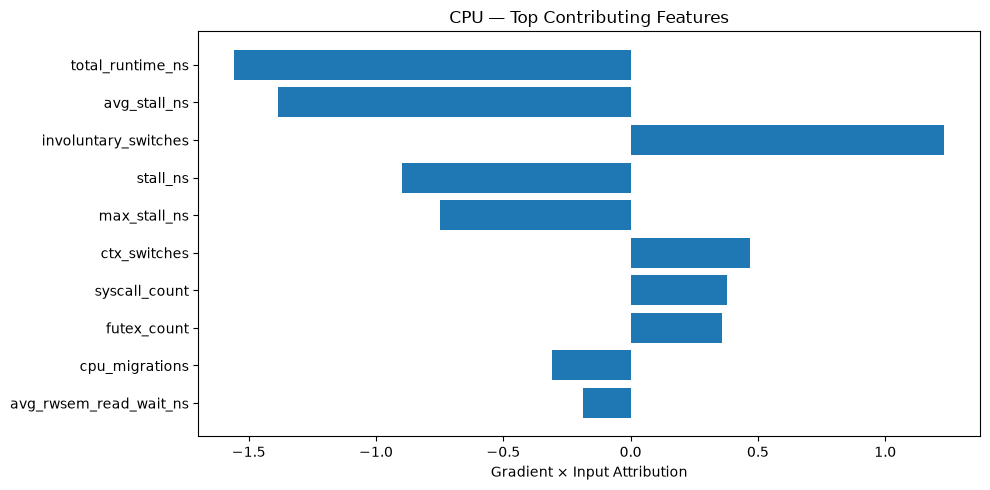

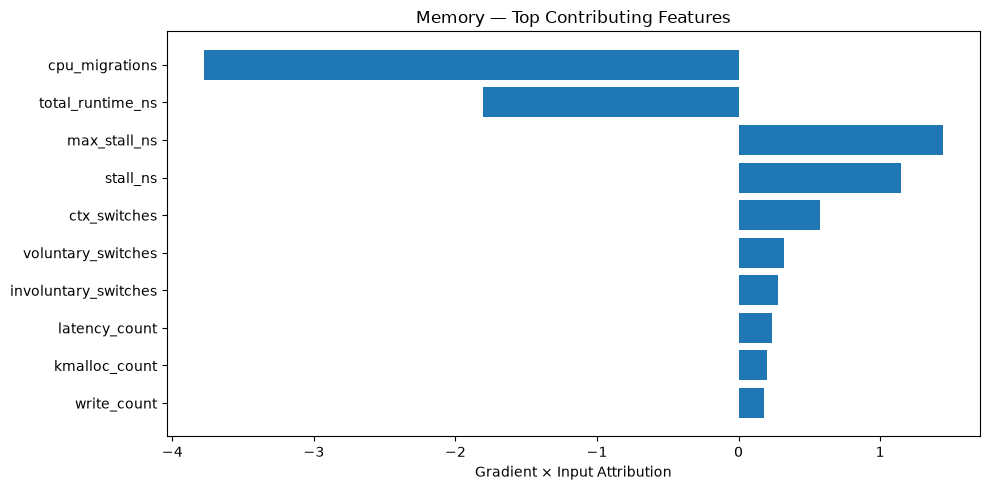

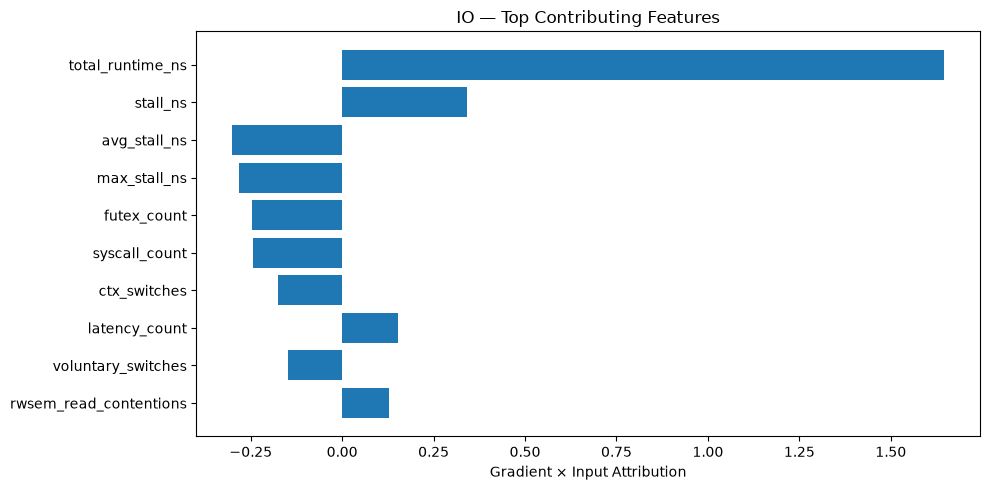

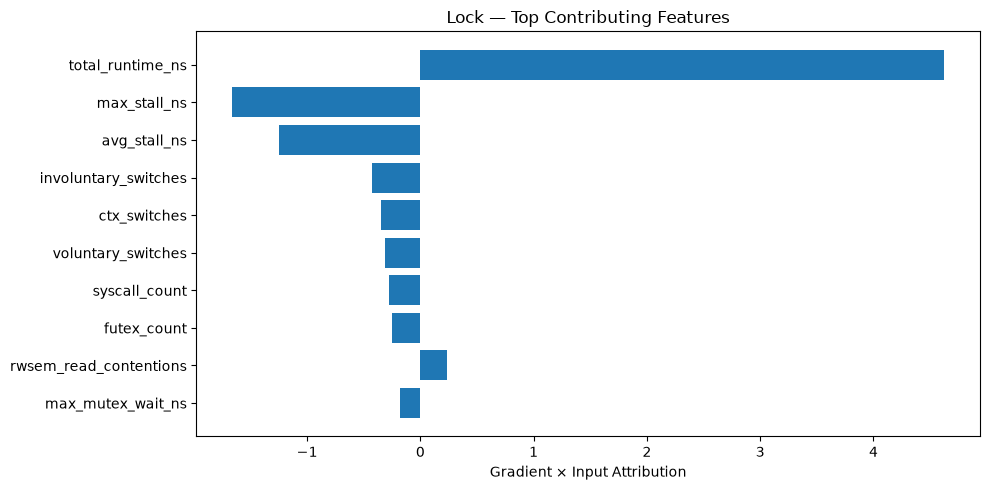

In [1]:
# ============================================================
# SINGLE TEST CASE — LOAD POINTERS + PREDICTION + ATTRIBUTION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ARTIFACT_DIR = "pipeline_comparison_artifacts"

CHECKPOINT = os.path.join(
    ARTIFACT_DIR,
    "focal_asl_only_best.pt"
)

SCALER_PATH = os.path.join(
    ARTIFACT_DIR,
    "feature_scaler.pkl"
)

FEATURES_PATH = os.path.join(
    ARTIFACT_DIR,
    "attribution_feature_cols.json"
)

TARGETS_PATH = os.path.join(
    ARTIFACT_DIR,
    "attribution_target_cols.json"
)

DATASET_PATH = "attribution_dataset.csv"


# ------------------------------------------------------------
# 2. Load saved pointers / metadata
# ------------------------------------------------------------

ATTR_FEATURES = json.load(
    open(FEATURES_PATH)
)

TARGET_COLS = json.load(
    open(TARGETS_PATH)
)

scaler = joblib.load(
    SCALER_PATH
)


print("=" * 70)
print("LOADED ARTIFACTS")
print("=" * 70)

print("Model      :", CHECKPOINT)
print("Scaler     :", SCALER_PATH)
print("Features   :", len(ATTR_FEATURES))
print("Targets    :", TARGET_COLS)


# ------------------------------------------------------------
# 3. Load attribution dataset
# ------------------------------------------------------------

df = pd.read_csv(DATASET_PATH)

print("\nDataset shape:", df.shape)


# ------------------------------------------------------------
# 4. Select ONE test case
# ------------------------------------------------------------
# Just for demonstration, we take one row from the dataset.
#
# IMPORTANT:
# This is only a demonstration of prediction + attribution.
# It is NOT being claimed as an unseen test-set sample.

TEST_INDEX = 0

test_case = df.iloc[[TEST_INDEX]][ATTR_FEATURES].copy()


print("\n" + "=" * 70)
print("SINGLE INPUT TEST CASE")
print("=" * 70)

display(test_case)


# ------------------------------------------------------------
# 5. Scale input
# ------------------------------------------------------------

test_scaled = scaler.transform(
    test_case
)


# ------------------------------------------------------------
# 6. Model architecture
# ------------------------------------------------------------

class BottleneckMLP(torch.nn.Module):

    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 64),
            torch.nn.ReLU(),

            torch.nn.Linear(64, 24),
            torch.nn.ReLU(),

            torch.nn.Linear(24, 16),
            torch.nn.ReLU(),

            torch.nn.Linear(16, output_dim)
        )

    def forward(self, x):
        return self.network(x)


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


model = BottleneckMLP(
    input_dim=len(ATTR_FEATURES),
    output_dim=len(TARGET_COLS)
).to(DEVICE)


# ------------------------------------------------------------
# 7. Load trained weights
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(
        CHECKPOINT,
        map_location=DEVICE
    )
)

model.eval()


# ------------------------------------------------------------
# 8. Generate prediction
# ------------------------------------------------------------

test_tensor = torch.tensor(
    test_scaled,
    dtype=torch.float32,
    device=DEVICE
)

test_tensor.requires_grad_(True)

logits = model(test_tensor)

probabilities = torch.sigmoid(
    logits
).detach().cpu().numpy()[0]

predictions = (
    probabilities >= 0.50
).astype(int)


# ------------------------------------------------------------
# 9. Display prediction
# ------------------------------------------------------------

prediction_df = pd.DataFrame({

    "Bottleneck":
        TARGET_COLS,

    "Probability":
        np.round(probabilities, 4),

    "Prediction":
        predictions
})



print("Model Pred")


display(prediction_df)


# ------------------------------------------------------------
# 10. Gradient × Input attribution
# ------------------------------------------------------------

logits = model(test_tensor)

attributions = []


for target_idx, target_name in enumerate(TARGET_COLS):

    model.zero_grad()

    if test_tensor.grad is not None:
        test_tensor.grad.zero_()

    logits[0, target_idx].backward(
        retain_graph=True
    )

    gradient = (
        test_tensor.grad[0]
        .detach()
        .cpu()
        .numpy()
    )

    input_values = (
        test_tensor[0]
        .detach()
        .cpu()
        .numpy()
    )

    attribution = (
        gradient * input_values
    )

    attributions.append(
        attribution
    )


attributions = np.array(
    attributions
)


# ------------------------------------------------------------
# 11. Display top 10 features for every output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE ATTRIBUTIONS")
print("=" * 70)


for target_idx, target_name in enumerate(TARGET_COLS):

    attribution = attributions[target_idx]

    top_indices = np.argsort(
        np.abs(attribution)
    )[::-1][:10]


    attribution_df = pd.DataFrame({

        "Feature": [
            ATTR_FEATURES[i]
            for i in top_indices
        ],

        "Input Value": [
            test_case.iloc[0, i]
            for i in top_indices
        ],

        "Attribution": [
            attribution[i]
            for i in top_indices
        ]

    })


    attribution_df["Attribution"] = (
        attribution_df["Attribution"]
        .round(6)
    )


    print(f"\n--- {target_name} ---")

    display(attribution_df)


# ------------------------------------------------------------
# 12. Plot attribution for predicted bottlenecks
# ------------------------------------------------------------

for target_idx, target_name in enumerate(TARGET_COLS):

    # Only visualize outputs predicted as 1
    if predictions[target_idx] == 0:
        continue


    attribution = attributions[target_idx]

    top_indices = np.argsort(
        np.abs(attribution)
    )[::-1][:10]


    features = [
        ATTR_FEATURES[i]
        for i in top_indices
    ]

    values = [
        attribution[i]
        for i in top_indices
    ]


    plt.figure(figsize=(10, 5))

    plt.barh(
        features[::-1],
        values[::-1]
    )

    plt.xlabel(
        "Gradient × Input Attribution"
    )

    plt.title(
        f"{target_name} — Top Contributing Features"
    )

    plt.tight_layout()
    plt.show()